In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [7]:
from pathlib import Path
import pandas as pd

dataset_path = Path("data_set") / "auto-mpg.csv"

if dataset_path.exists():
    df = pd.read_csv(dataset_path)
    print("Dataset loaded successfully!")
else:
    print("Dataset not found!")

Dataset loaded successfully!


In [3]:
df = pd.read_csv(file_name)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [4]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.301508,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.280676,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,94.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


In [5]:
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82,2720,19.4,82,1,chevy s-10


In [6]:
cdf = df[['cylinders','displacement','horsepower','weight','acceleration','model year','mpg']]
cdf.head()

,cylinders,displacement,horsepower,weight,acceleration,model year,mpg
0,8,307.0,130,3504,12.0,70,18.0
1,8,350.0,165,3693,11.5,70,15.0
2,8,318.0,150,3436,11.0,70,18.0
3,8,304.0,150,3433,12.0,70,16.0
4,8,302.0,140,3449,10.5,70,17.0


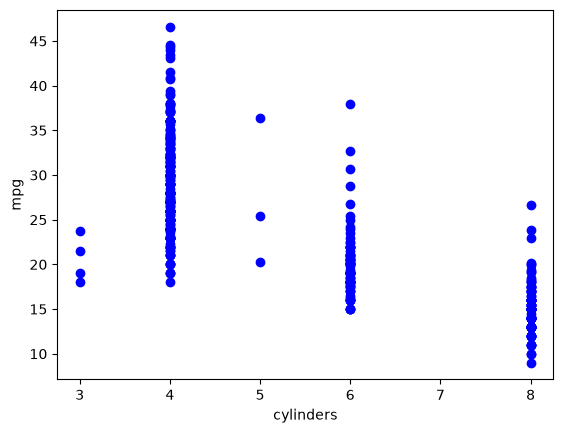

In [7]:
plt.scatter(cdf.cylinders , cdf.mpg , color = 'blue')
plt.xlabel('cylinders')
plt.ylabel('mpg')
plt.show()

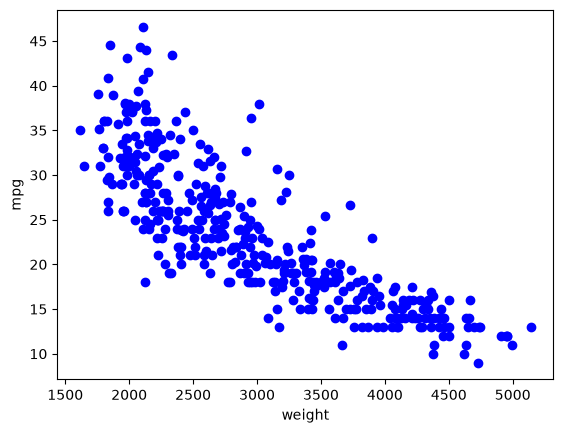

In [8]:
plt.scatter(cdf.weight , cdf.mpg , color = 'blue')
plt.xlabel('weight')
plt.ylabel('mpg')
plt.show()

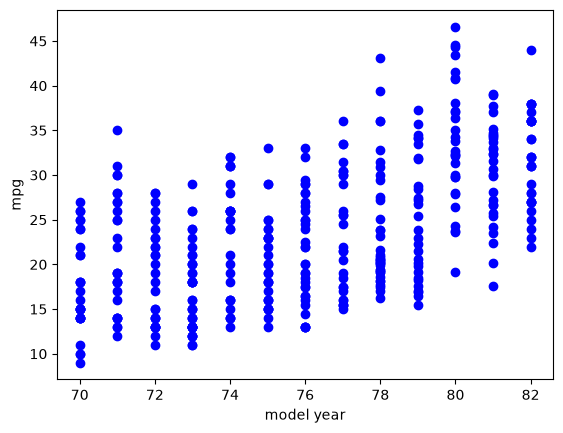

In [9]:
plt.scatter(
    cdf['model year'] ,
    cdf.mpg ,
    color = "blue"
)
plt.xlabel("model year")
plt.ylabel("mpg")
plt.show()

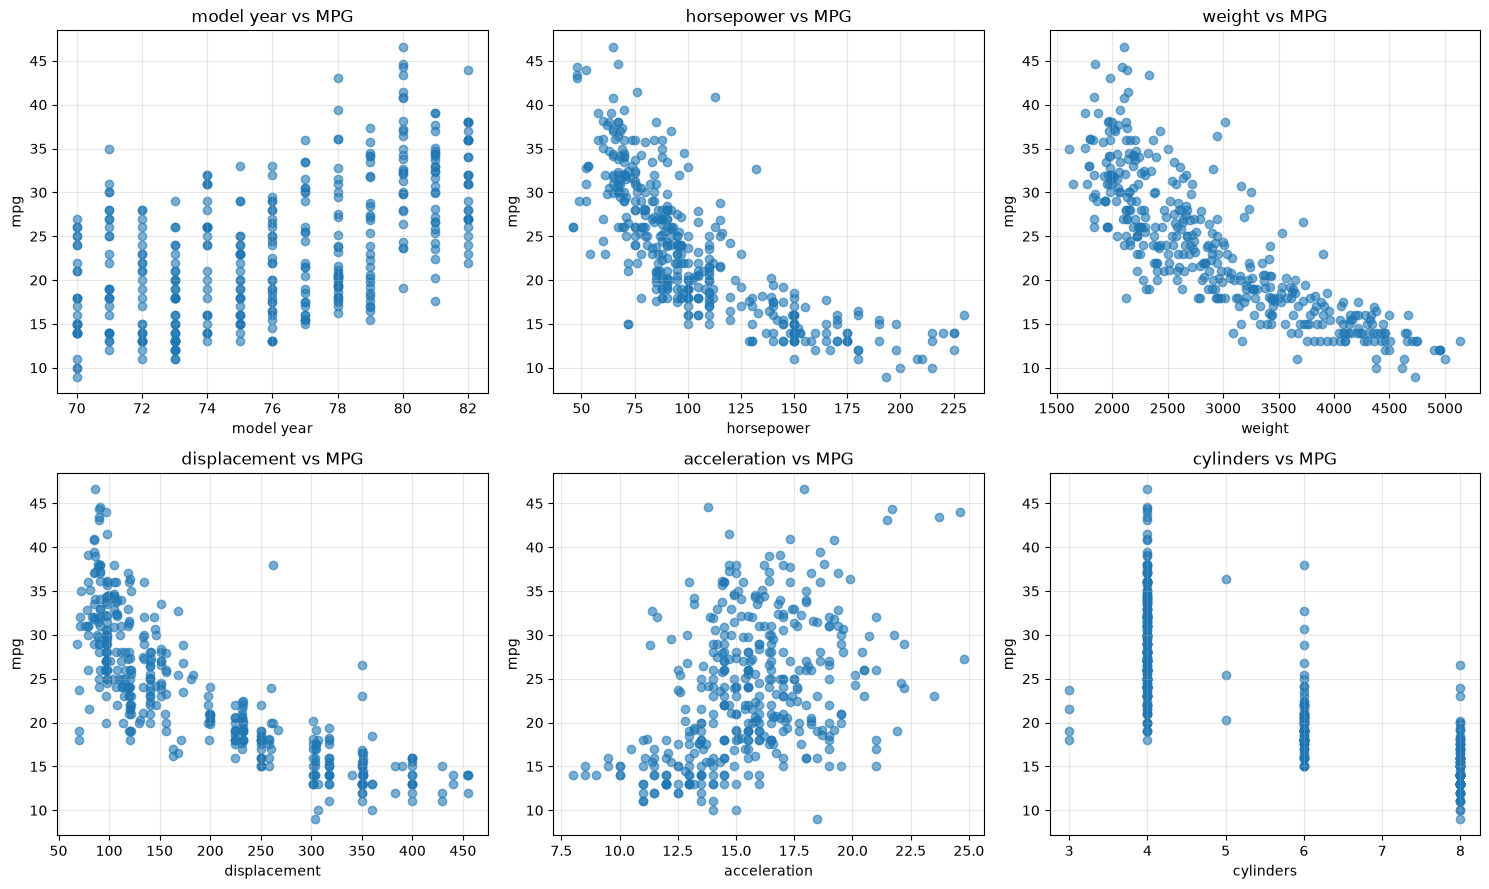

In [10]:
features = [
    "model year",
    "horsepower",
    "weight",
    "displacement",
    "acceleration",
    "cylinders"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), features):
    ax.scatter(cdf[feature], cdf["mpg"], alpha=0.6)
    ax.set_xlabel(feature)
    ax.set_ylabel("mpg")
    ax.set_title(f"{feature} vs MPG")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
msk = np.random.rand(len(df)) < 0.8
train = cdf[msk]
test  = cdf[~msk]

print(f"train set count: {len(train)}")
print(f"test set count: {len(test)}")

train set count: 330
test set count: 68


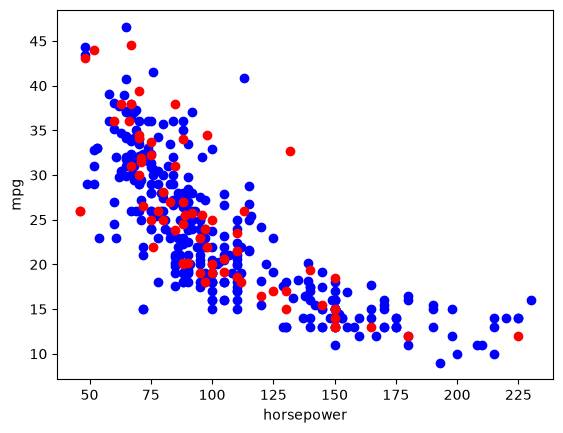

In [16]:
fig = plt.figure()
ax1 = fig.add_subplot(111)
ax1.scatter(train.horsepower , train.mpg , color = 'blue')
ax1.scatter(test.horsepower , test.mpg , color = 'red')
plt.xlabel('horsepower')
plt.ylabel('mpg')
plt.show()

In [41]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn import linear_model

train_x = np.asanyarray(train[['horsepower']])
train_y = np.asanyarray(train[['mpg']])

test_x = np.asanyarray(test[['horsepower']])
test_y = np.asanyarray(test[['mpg']])

print(train_x [:3])
poly = PolynomialFeatures(degree=2)
train_x_poly = poly.fit_transform(train_x)
train_x_poly [10]

[[130]
 [165]
 [150]]


array([1.00e+00, 1.70e+02, 2.89e+04])

In [46]:
clf = linear_model.LinearRegression()
train_y_ = clf.fit(train_x_poly , train_y)

print("coffionts: " , clf.coef_)
print("intercept: " , clf.intercept_)

coffionts:  [[ 0.         -0.45221293  0.00118889]]
intercept:  [55.8443369]


Text(0, 0.5, 'mpg')

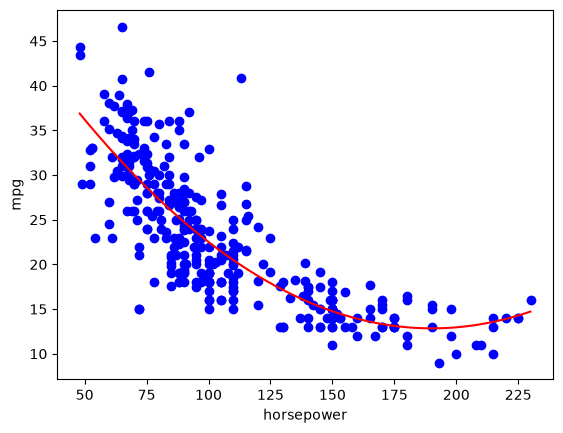

In [59]:
plt.scatter(train.horsepower , train.mpg , color = 'blue')
XX = np.arange(train.horsepower.min() , train.horsepower.max() , 0.1)
yy = clf.intercept_[0] + clf.coef_[0][1] * XX + clf.coef_[0][2] * np.power(XX , 2)
plt.plot(XX , yy , '-r')
plt.xlabel('horsepower')
plt.ylabel('mpg')

In [44]:
from sklearn.metrics import r2_score

test_x_poly = poly.transform(test_x)
test_y_ = clf.predict(test_x_poly)

print("Mean absolute error: %.2f" % np.mean(np.absolute(test_y_ - test_y)))
print("Residual sum of squares (MSE): %.2f" % np.mean((test_y_ - test_y) ** 2))
print("R2-score: %.2f" % r2_score(test_y,test_y_ ) )

Mean absolute error: 3.79
Residual sum of squares (MSE): 26.97
R2-score: 0.60
